# Week 4 · Dissecting an RLDS dataset

Goal: open one RLDS dataset and inspect its structure before writing any converter code.

## What these datasets are

- **Open X-Embodiment (OXE):** a collection of ~1M robot episodes from ~60 labs, published by Google DeepMind (paper: arXiv 2310.08864). Each lab contributed its own recordings, so schemas differ episode by episode. That is the "data mess" this week converts.
- **DROID:** ~76k teleoperation episodes of table-top tasks, recorded across many labs with the same Franka arm rig. Canonical format is also RLDS.
- **RLDS (Robot Learning Data Set):** Google's storage format for robot episodes. Episodes are stored as **TFRecords**.
- **TFRecord:** a plain file format — a sequence of records, each record one serialized protobuf. No schema enforced in the file itself.
- **tfds (`tensorflow_datasets`):** the catalog library. It downloads datasets and decodes their records. Its main object is the **builder**: one class per dataset that knows the dataset's name, splits, feature shapes, and download URLs.

## Week 4 slices

- OXE: `columbia_cairlab_pusht_real` — a real robot playing PushT, the same task I simulated in Week 3.
- DROID: a few episodes only. The full dataset is too large for this notebook.

## The plan for this notebook

Goal: dissect one RLDS dataset end to end — catalog, metadata, episode,
step, each feature's real values. The converter I write later will copy
what I saw here, not what the README promised.

1. **Find the builders.** Confirm the dataset names in the tfds catalog.
2. **Builder metadata.** Read splits, episode counts, and the declared
   shape and dtype of every feature.
3. **Open one episode.** Download the test split and print the step
   count of the first episode.
4. **Open one step.** Print the real values inside one step. Settle two
   hypotheses: are `world_vector` values near zero (deltas) or large
   (absolute targets), and what do the two `robot_state` numbers
   measure?
5. **Check the images.** The RLDS README says images are stored as
   encoded JPEG/PNG bytes. The feature declares a decoded shape. Find
   out what the data actually contains.
6. **Repeat Steps 2 to 4 on `robotics:droid`.** Compare the schemas of
   two datasets in the same format. This comparison is the core
   evidence for the Week 4 video.

## Step 1: Find the two builders in the tfds catalog

`tfds.list_builders()` returns a list of strings, one name per dataset tfds can build.

The catalog has two parts:
- **official** builders, maintained by the tfds team — plain names.
- **community** builders, contributed code — hidden unless `with_community_datasets=True`, and their names carry a `community/` prefix.

OXE and DROID builders are community builders. This cell searches the full catalog for the two names. It only prints strings; nothing downloads yet.

In [2]:
import tensorflow_datasets as tfds

names = tfds.list_builders(with_community_datasets=True)

W0000 00:00:1795584322.188658  518918 google_auth_provider.cc:196] All attempts to get a Google authentication bearer token failed, returning an empty token. Retrieving token from files failed with "NOT_FOUND: Could not locate the credentials file.". Retrieving token from GCE failed with "FAILED_PRECONDITION: Error executing an HTTP request: libcurl code 6 meaning 'Could not resolve hostname', error details: Could not resolve host: metadata.google.internal".


In [7]:
print(sorted(n for n in names if "pusht_real" in n or "droid" in n))

['columbia_cairlab_pusht_real', 'robotics:columbia_cairlab_pusht_real', 'robotics:droid', 'robotics:droid_100', 'robotics:droid_raw']


## Step 2 — Open the builder, read its metadata

`tfds.builder(name)` returns the builder object. The builder holds the
dataset's self-description. No episode data downloads here. The builder
fetches two small JSON files: the dataset description and the checksums.

Objects in this cell:

- `builder.info` — a `DatasetInfo` object. It records the version, the
  total size, the splits, and the features.
- `builder.info.splits` — a dict. One entry per split (`train`, `test`).
  Each entry carries `num_examples`. In RLDS one example is one episode,
  so `num_examples` counts episodes, not frames.
- `builder.info.features` — a dict. One entry per step field. Each entry
  declares `dtype` and `shape`. An image feature declares itself as an
  image. We decode images in a later cell, not here.

This cell prints: the splits with episode counts, then the feature names
with dtype and shape.

In [37]:
columbia_builder = tfds.builder("robotics:columbia_cairlab_pusht_real")

In [ ]:
for k, v in columbia_builder.info.splits.items():
    print(k, v.num_examples)

train 122
test 14


In [ ]:
for k, v in columbia_builder.info.features.items():
    for x, y in v.items():
        print(x, y.shape, y.dtype)

is_last () <dtype: 'bool'>
observation {'robot_state': (2,), 'image': (240, 320, 3), 'wrist_image': (240, 320, 3), 'natural_language_instruction': (), 'natural_language_embedding': (512,)} {'robot_state': tf.float32, 'image': tf.uint8, 'wrist_image': tf.uint8, 'natural_language_instruction': tf.string, 'natural_language_embedding': tf.float32}
reward () <dtype: 'float32'>
is_terminal () <dtype: 'bool'>
action {'terminate_episode': (), 'rotation_delta': (3,), 'world_vector': (3,), 'gripper_closedness_action': ()} {'terminate_episode': tf.float32, 'rotation_delta': tf.float32, 'world_vector': tf.float32, 'gripper_closedness_action': tf.float32}
is_first () <dtype: 'bool'>


## Step 3: Open one episode

**Open one episode.** Download the test split and print the step
   count of the first episode.

New objects:

- `builder.as_dataset(split="test")` downloads the test split on first
  call. It returns a `tf.data.Dataset`. A `tf.data.Dataset` is
  TensorFlow's lazy sequence of records, similar to a Spark RDD:
  elements are produced as you iterate. Here each element is one
  episode.
- `iter(dataset)` returns a Python iterator over the dataset.
- `next(iterator)` returns the first element: the first episode.
- `episode.cardinality()` returns the number of steps in the episode.
  An episode is itself a `tf.data.Dataset`, and its elements are steps.
  Wrap the result in `int()`.

Prediction: the first episode contains between 50 and 500 steps.

In [39]:
columbia_ds = columbia_builder.as_dataset(split="test")
episode0 = next(iter(columbia_ds))

I0000 00:00:1795597037.599239  662459 tf_record_dataset_op.cc:396] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608


In [56]:
steps_ds = episode0["steps"]
n_steps = int(steps_ds.cardinality())
print("first episode steps:", n_steps)

step0 = next(iter(steps_ds))
print("step keys:", sorted(step0.keys()))


first episode steps: 223
step keys: ['action', 'is_first', 'is_last', 'is_terminal', 'observation', 'reward']


## Step 4 — Open one step, print the values

`step0` is a dict of eager tensors. `.numpy()` converts one tensor to a
NumPy array for reading. Two hypotheses get tested here:

- H1: `world_vector` values sit near zero. Small numbers mean motion
  deltas, not absolute targets.
- H2: `robot_state` holds two numbers describing the arm's hand on the
  table plane.

In [57]:
print("reward:", step0["reward"].numpy())
print("is_first / is_last / is_terminal:",
      step0["is_first"].numpy(), step0["is_last"].numpy(), step0["is_terminal"].numpy())

print("robot_state:", step0["observation"]["robot_state"].numpy())
print("language:", step0["observation"]["natural_language_instruction"].numpy())

print("world_vector:", step0["action"]["world_vector"].numpy())
print("rotation_delta:", step0["action"]["rotation_delta"].numpy())
print("gripper_closedness_action:", step0["action"]["gripper_closedness_action"].numpy())
print("terminate_episode:", step0["action"]["terminate_episode"].numpy())

reward: 0.0
is_first / is_last / is_terminal: True False False
robot_state: [ 0.4189453  -0.19125372]
language: b'The task requires pushing a T-shaped block (gray) to a fixed target (green) with a circular end-effector (blue). Both observation and control frequencies are 10Hz.'
world_vector: [1.8429362e-05 2.5074698e-05 0.0000000e+00]
rotation_delta: [0. 0. 0.]
gripper_closedness_action: 0.0
terminate_episode: 0.0


## Step 5 — Check the image

The RLDS README says images are stored as encoded JPEG/PNG bytes. The
feature declared shape (240, 320, 3). tfds decodes during reading, so
the value here should already be a NumPy array of pixels. Values in the
range 0 to 255 with no NaN confirm a real image.

type: <class 'numpy.ndarray'> shape: (240, 320, 3) dtype: uint8
min: 0 max: 205


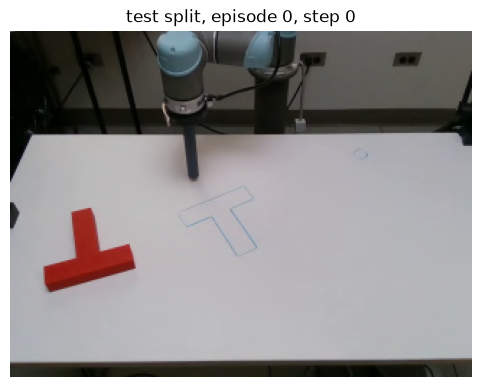

In [58]:
import matplotlib.pyplot as plt

arr = step0["observation"]["image"].numpy()
print("type:", type(arr), "shape:", arr.shape, "dtype:", arr.dtype)
print("min:", arr.min(), "max:", arr.max())

plt.figure(figsize=(6, 4.5))
plt.imshow(arr)
plt.title("test split, episode 0, step 0")
plt.axis("off")
plt.show()

## Step 6 — Compare schemas: DROID

Same format, second source. `tfds.builder(...)` alone reads only the
small metadata files, no episode data. If the step schemas of two
datasets in one format differ, "one format" does not mean "one schema".
That difference is the Week 4 thesis.

In [59]:
droid_builder = tfds.builder("robotics:droid")

print("--- splits (episodes per split) ---")
for k, v in droid_builder.info.splits.items():
    print(k, v.num_examples)

print("--- features ---")
for k, v in droid_builder.info.features.items():
    if hasattr(v, "items"):
        for x, y in v.items():
            print(k, x, getattr(y, "shape", None), getattr(y, "dtype", None))
    else:
        print(k, v.shape, v.dtype)

--- splits (episodes per split) ---
train 95658
--- features ---
episode_metadata recording_folderpath () <dtype: 'string'>
episode_metadata file_path () <dtype: 'string'>
steps language_instruction_3 () <dtype: 'string'>
steps observation {'exterior_image_1_left': (180, 320, 3), 'exterior_image_2_left': (180, 320, 3), 'cartesian_position': (6,), 'wrist_image_left': (180, 320, 3), 'joint_position': (7,), 'gripper_position': (1,)} {'exterior_image_1_left': tf.uint8, 'exterior_image_2_left': tf.uint8, 'cartesian_position': tf.float64, 'wrist_image_left': tf.uint8, 'joint_position': tf.float64, 'gripper_position': tf.float64}
steps action (7,) <dtype: 'float64'>
steps discount () <dtype: 'float32'>
steps is_last () <dtype: 'bool'>
steps language_instruction_2 () <dtype: 'string'>
steps reward () <dtype: 'float32'>
steps is_terminal () <dtype: 'bool'>
steps action_dict {'gripper_position': (1,), 'cartesian_position': (6,), 'joint_position': (7,), 'gripper_velocity': (1,), 'joint_velocity':

## Findings

- RLDS episode = stream of steps. Step fields: observation, action,
  reward, is_first, is_last, is_terminal.
- H1 confirmed: `world_vector` holds motion deltas. Values ~0.00002 at
  step 0. Actions command the hand, not the joints.
- H2 supported: `robot_state` (2,) holds meter-scale hand position. It
  does not hold the block.
- The language field is a templated scene description. It reports 10 Hz
  control frequency.
- Images arrive decoded as (240, 320, 3) uint8 arrays. The README's
  encoded-bytes claim describes storage on disk.
- DROID, same RLDS format, different schema: 3 cameras, (7,) action
  vector plus 6 redundant representations in `action_dict`, joint and
  cartesian states, discount, file provenance, float64.
- Conclusion: RLDS standardizes storage, not schema. A converter must
  map per dataset.